<a href="https://colab.research.google.com/github/abdealimak/ML-CW/blob/main/Linear_Regression_Diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import pandas as pd
from sklearn.datasets import load_diabetes

diabetes =load_diabetes()


print(diabetes.keys())
print(diabetes.feature_names)
print(diabetes.DESCR)

dict_keys(['data', 'target', 'frame', 'DESCR', 'feature_names', 'data_filename', 'target_filename', 'data_module'])
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4   

In [27]:
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df["Disease_Progression"] = diabetes.target
print(df.iloc[0])
df.head()

age                      0.038076
sex                      0.050680
bmi                      0.061696
bp                       0.021872
s1                      -0.044223
s2                      -0.034821
s3                      -0.043401
s4                      -0.002592
s5                       0.019907
s6                      -0.017646
Disease_Progression    151.000000
Name: 0, dtype: float64


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Disease_Progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [13]:
print(diabetes.data.shape)

(442, 10)


In [14]:
print(diabetes.data[:5])

[[ 0.03807591  0.05068012  0.06169621  0.02187239 -0.0442235  -0.03482076
  -0.04340085 -0.00259226  0.01990749 -0.01764613]
 [-0.00188202 -0.04464164 -0.05147406 -0.02632753 -0.00844872 -0.01916334
   0.07441156 -0.03949338 -0.06833155 -0.09220405]
 [ 0.08529891  0.05068012  0.04445121 -0.00567042 -0.04559945 -0.03419447
  -0.03235593 -0.00259226  0.00286131 -0.02593034]
 [-0.08906294 -0.04464164 -0.01159501 -0.03665608  0.01219057  0.02499059
  -0.03603757  0.03430886  0.02268774 -0.00936191]
 [ 0.00538306 -0.04464164 -0.03638469  0.02187239  0.00393485  0.01559614
   0.00814208 -0.00259226 -0.03198764 -0.04664087]]


In [15]:
print(diabetes.target[:5])

[151.  75. 141. 206. 135.]


In [28]:
df["Disease_Progression"]= diabetes.target
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Disease_Progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [29]:
print(df.columns)

Index(['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6',
       'Disease_Progression'],
      dtype='object')


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  442 non-null    float64
 1   sex                  442 non-null    float64
 2   bmi                  442 non-null    float64
 3   bp                   442 non-null    float64
 4   s1                   442 non-null    float64
 5   s2                   442 non-null    float64
 6   s3                   442 non-null    float64
 7   s4                   442 non-null    float64
 8   s5                   442 non-null    float64
 9   s6                   442 non-null    float64
 10  Disease_Progression  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [31]:
df.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Disease_Progression
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


In [32]:
print(df.isnull().sum())

age                    0
sex                    0
bmi                    0
bp                     0
s1                     0
s2                     0
s3                     0
s4                     0
s5                     0
s6                     0
Disease_Progression    0
dtype: int64


In [38]:
X = df.drop("Disease_Progression", axis=1)
print(X.head())

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  


In [74]:
y = df["Disease_Progression"]
print(y.head())

0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: Disease_Progression, dtype: float64


In [75]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [76]:
print("Training Data:", X_train.shape, y_train.shape)
print("Testing Data:", X_test.shape, y_test.shape)

Training Data: (353, 10) (353,)
Testing Data: (89, 10) (89,)


In [77]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

In [78]:
print("Intercept =", model.intercept_)

Intercept = 151.34560453985995


In [79]:
coefficients = pd.DataFrame({"Features":X.columns, "Coefficients":model.coef_})
print(coefficients)
print("Coefficients =", model.coef_)

  Features  Coefficients
0      age     37.904021
1      sex   -241.964362
2      bmi    542.428759
3       bp    347.703844
4       s1   -931.488846
5       s2    518.062277
6       s3    163.419983
7       s4    275.317902
8       s5    736.198859
9       s6     48.670657
Coefficients = [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]


In [80]:
print("Regression Equation")
print("\n Disease Progression = ")
print(model.intercept_)
for feature, coefficient in zip(X.columns, model.coef_):
    print(f" + {coefficient} * {feature}")

Regression Equation

 Disease Progression = 
151.34560453985995
 + 37.904021350074984 * age
 + -241.96436231273995 * sex
 + 542.4287585162899 * bmi
 + 347.70384391385636 * bp
 + -931.4888458835163 * s1
 + 518.0622769833376 * s2
 + 163.41998299131035 * s3
 + 275.3179015786484 * s4
 + 736.1988589046839 * s5
 + 48.67065743196543 * s6


In [81]:
predictions = model.predict(X_test)
print(predictions[:10])

[139.5475584  179.51720835 134.03875572 291.41702925 123.78965872
  92.1723465  258.23238899 181.33732057  90.22411311 108.63375858]


In [82]:
comparision = pd.DataFrame({"Actual":y_test.values, "Predicted":predictions})
print(comparision.head(10))

   Actual   Predicted
0   219.0  139.547558
1    70.0  179.517208
2   202.0  134.038756
3   230.0  291.417029
4   111.0  123.789659
5    84.0   92.172347
6   242.0  258.232389
7   272.0  181.337321
8    94.0   90.224113
9    96.0  108.633759


In [83]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("Mean Squared Error:", mean_squared_error(y_test, predictions))
print("R2 Score:", r2_score(y_test, predictions))

Mean Absolute Error: 42.79409467959994
Mean Squared Error: 2900.193628493482
R2 Score: 0.4526027629719195


In [84]:
new_patient = pd.DataFrame(
    [diabetes.data[0]],
    columns=diabetes.feature_names
)
prediction = model.predict(new_patient)
print("Predicted Disease Progression: ", prediction)

Predicted Disease Progression:  [210.74209145]


In [85]:
actual = y.iloc[0]
prediction = model.predict(X.iloc[[0]])
print("Actual Disease Progression: ", actual)
print("Predicted Disease Progression: ", prediction[0])

Actual Disease Progression:  151.0
Predicted Disease Progression:  210.7420914473924


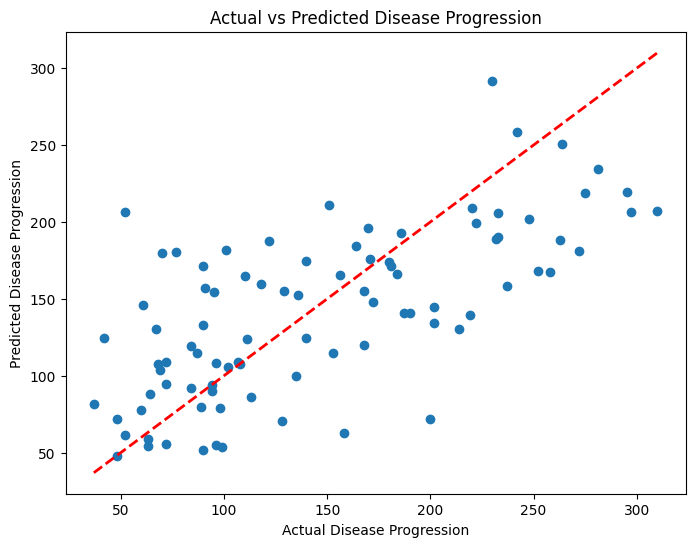

In [86]:
import matplotlib.pyplot as plt

predictions = model.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, predictions)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Disease Progression")
plt.ylabel("Predicted Disease Progression")
plt.title("Actual vs Predicted Disease Progression")
plt.show()

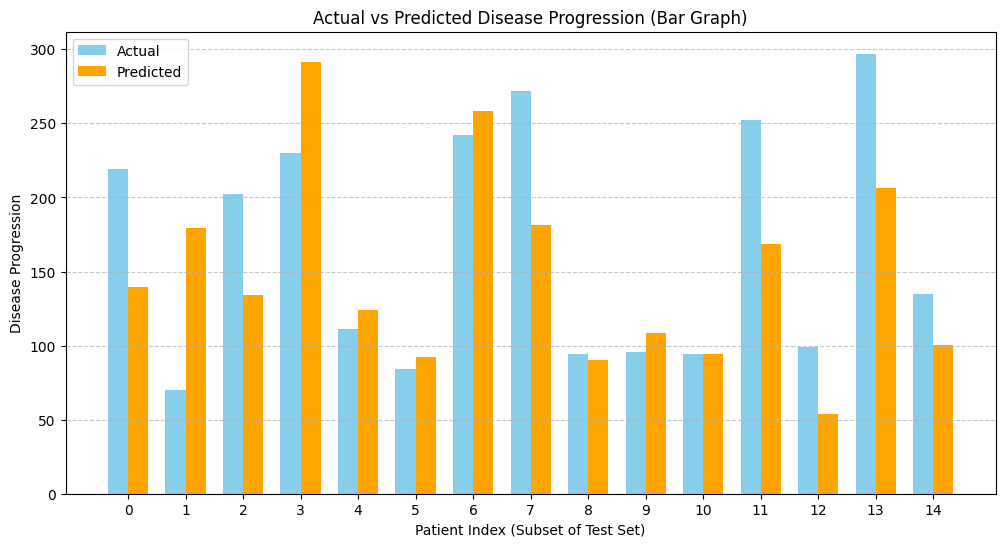

In [88]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

predictions = model.predict(X_test)

comparison_df = pd.DataFrame({"Actual": y_test.values, "Predicted": predictions}).head(15)

x = np.arange(len(comparison_df))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar(x - width/2, comparison_df["Actual"], width, label="Actual", color="skyblue")
plt.bar(x + width/2, comparison_df["Predicted"], width, label="Predicted", color="orange")

plt.xlabel("Patient Index (Subset of Test Set)")
plt.ylabel("Disease Progression")
plt.title("Actual vs Predicted Disease Progression (Bar Graph)")
plt.xticks(x, comparison_df.index)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

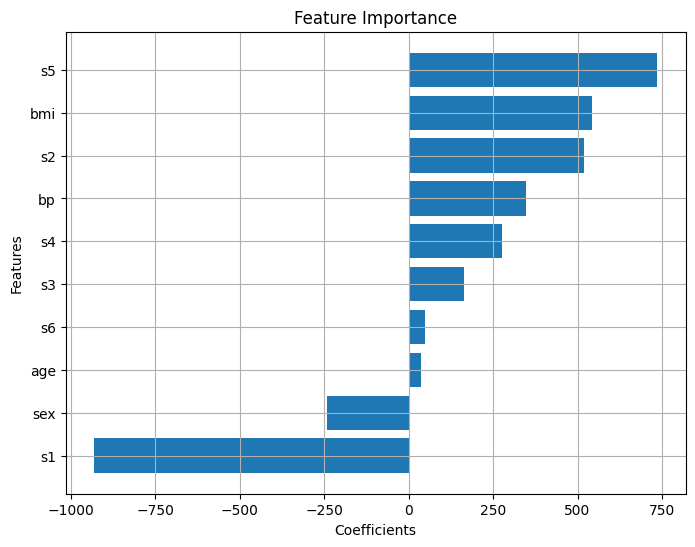

In [87]:
coefficients = pd.DataFrame({"Features":X.columns, "Coefficients":model.coef_})

coefficients.sort_values(by="Coefficients",inplace=True)
plt.figure(figsize=(8, 6))
plt.barh(coefficients["Features"], coefficients["Coefficients"])
plt.xlabel("Coefficients")
plt.ylabel("Features")
plt.title("Feature Importance")
plt.grid(True)
plt.show()
